In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.15.0+cpu
Device : cpu


## 1. Chargement du dataset MNIST

Images de chiffres manuscrits en niveaux de gris, de taille 28 × 28 = 784 pixels, avec un label entre 0 et 9.

In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

100.0%
100.0%
100.0%
100.0%


Train : 60000
Test  : 10000


Forme d'un lot : torch.Size([128, 1, 28, 28])


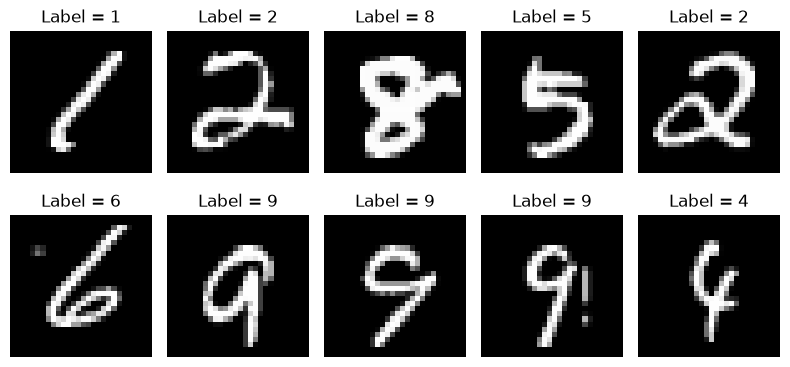

In [4]:
images, labels = next(iter(train_loader))
print("Forme d'un lot :", images.shape)

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Modèle discriminatif : apprendre P(y | x)

Le classifieur reçoit une image x et prédit sa classe y. Il **discrimine** les classes, mais il ne sait pas générer d'images.

In [5]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)


def train_classifier(model, loader, epochs=3):
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} - Loss = {total_loss/len(loader):.4f}")


train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4115
Epoch 2/3 - Loss = 0.1943
Epoch 3/3 - Loss = 0.1374


In [7]:
from torcheval.metrics import MulticlassAccuracy


@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    metric = MulticlassAccuracy(device=device)
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        metric.update(model(x), y)
    return metric.compute().item()


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy sur le test = {100 * accuracy:.2f}%")

c:\Users\ad\Desktop\TPs_IA\TP2_Modeles_Generatifs\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy sur le test = 96.37%


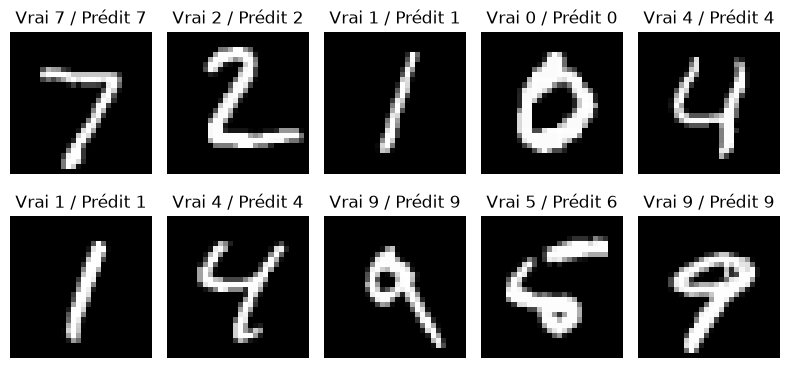

In [8]:
# Quelques prédictions sur le jeu de test
classifier.eval()
x, y = next(iter(test_loader))

with torch.no_grad():
    pred = classifier(x.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x[i].squeeze(), cmap="gray")
    ax.set_title(f"Vrai {y[i].item()} / Prédit {pred[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Auto-encodeur simple

x → Encoder → z → Decoder → x̂, avec x̂ ≈ x.

Les labels ne sont plus nécessaires : le modèle apprend à reconstruire son entrée. On choisit un espace latent de dimension 2 pour pouvoir le visualiser.

In [9]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))


ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [10]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)


def train_autoencoder(model, loader, epochs=5):
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} - Loss = {total_loss/len(loader):.4f}")


train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0650
Epoch 2/5 - Loss = 0.0515
Epoch 3/5 - Loss = 0.0474
Epoch 4/5 - Loss = 0.0452
Epoch 5/5 - Loss = 0.0439


### Évaluation : erreur de reconstruction sur le test

In [11]:
@torch.no_grad()
def evaluate_autoencoder(model, loader):
    model.eval()
    total_loss = 0
    for x, _ in loader:
        x = x.to(device)
        total_loss += ae_criterion(model(x), x).item()
    return total_loss / len(loader)


print(f"MSE de reconstruction (test) = {evaluate_autoencoder(ae, test_loader):.4f}")

MSE de reconstruction (test) = 0.0434


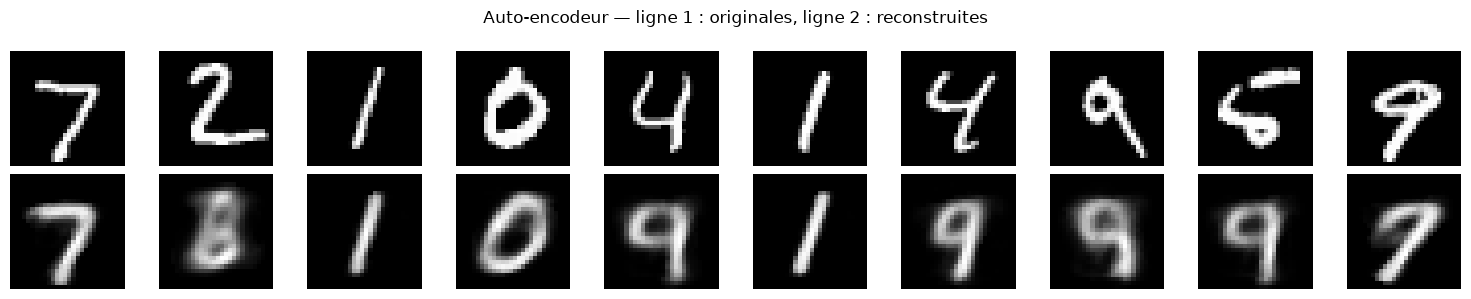

In [12]:
def afficher_reconstructions(model, titre, vae=False):
    model.eval()
    x, _ = next(iter(test_loader))
    x = x[:10].to(device)

    with torch.no_grad():
        x_hat = model(x)
        if vae:
            x_hat = x_hat[0]

    fig, axes = plt.subplots(2, 10, figsize=(15, 3))
    for i in range(10):
        axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
        axes[0, i].axis("off")
        axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
        axes[1, i].axis("off")
    fig.suptitle(f"{titre} — ligne 1 : originales, ligne 2 : reconstruites")
    plt.tight_layout()
    plt.show()


afficher_reconstructions(ae, "Auto-encodeur")

### Exploration : espace latent de l'auto-encodeur

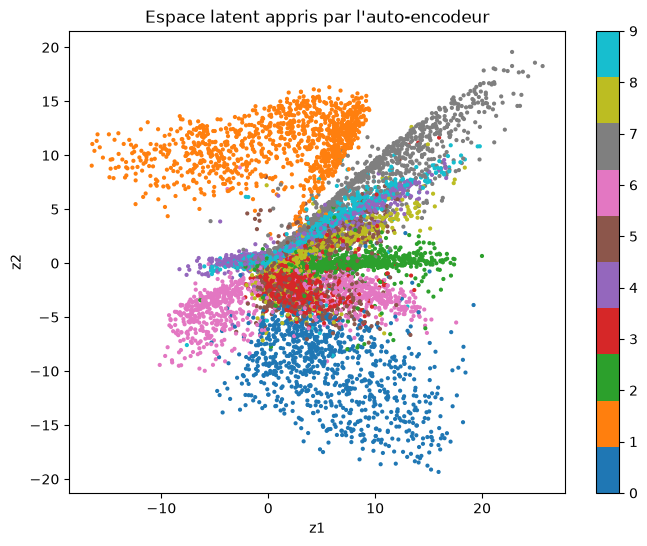

In [13]:
ae.eval()
zs, ys = [], []

with torch.no_grad():
    for x, y in test_loader:
        zs.append(ae.encode(x.to(device)).cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4, cmap="tab10")
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'auto-encodeur")
plt.colorbar(scatter)
plt.show()

### Exploration : générer chaque chiffre à partir de son vecteur latent moyen

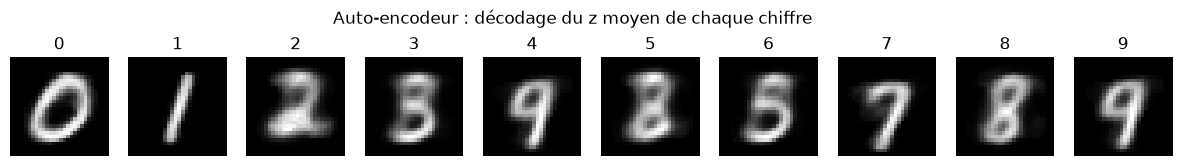

In [14]:
@torch.no_grad()
def z_moyen_par_chiffre(model, loader, vae=False):
    model.eval()
    sommes = {c: None for c in range(10)}
    nombres = {c: 0 for c in range(10)}

    for images, labels in loader:
        z = model.encode(images.to(device))
        if vae:
            z = z[0]           # on utilise mu
        for c in range(10):
            zc = z[labels.to(device) == c]
            if len(zc) == 0:
                continue
            s = zc.sum(dim=0, keepdim=True)
            sommes[c] = s if sommes[c] is None else sommes[c] + s
            nombres[c] += len(zc)

    return {c: sommes[c] / nombres[c] for c in range(10)}


@torch.no_grad()
def afficher_chiffres_moyens(model, loader, titre, vae=False):
    z_moy = z_moyen_par_chiffre(model, loader, vae)
    fig, axes = plt.subplots(1, 10, figsize=(15, 2))
    for c, ax in enumerate(axes):
        image = model.decode(z_moy[c]).cpu()
        ax.imshow(image[0, 0], cmap="gray")
        ax.set_title(str(c))
        ax.axis("off")
    fig.suptitle(titre)
    plt.show()


afficher_chiffres_moyens(ae, train_loader, "Auto-encodeur : décodage du z moyen de chaque chiffre")

### Exploration : interpolation entre deux chiffres

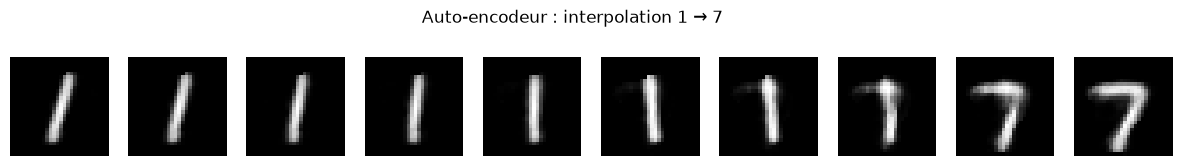

In [15]:
@torch.no_grad()
def interpolation(model, image_a, image_b, titre, vae=False, etapes=10):
    model.eval()
    za = model.encode(image_a.unsqueeze(0).to(device))
    zb = model.encode(image_b.unsqueeze(0).to(device))
    if vae:
        za, zb = za[0], zb[0]

    fig, axes = plt.subplots(1, etapes, figsize=(15, 2))
    for i, t in enumerate(torch.linspace(0, 1, etapes)):
        z = (1 - t) * za + t * zb
        axes[i].imshow(model.decode(z).cpu()[0, 0], cmap="gray")
        axes[i].axis("off")
    fig.suptitle(titre)
    plt.show()


# Une image de 1 et une image de 7 du jeu de test
image_1 = next(img for img, lab in test_dataset if lab == 1)
image_7 = next(img for img, lab in test_dataset if lab == 7)

interpolation(ae, image_1, image_7, "Auto-encodeur : interpolation 1 → 7")

### Limite de l'auto-encodeur : décoder des points latents choisis au hasard

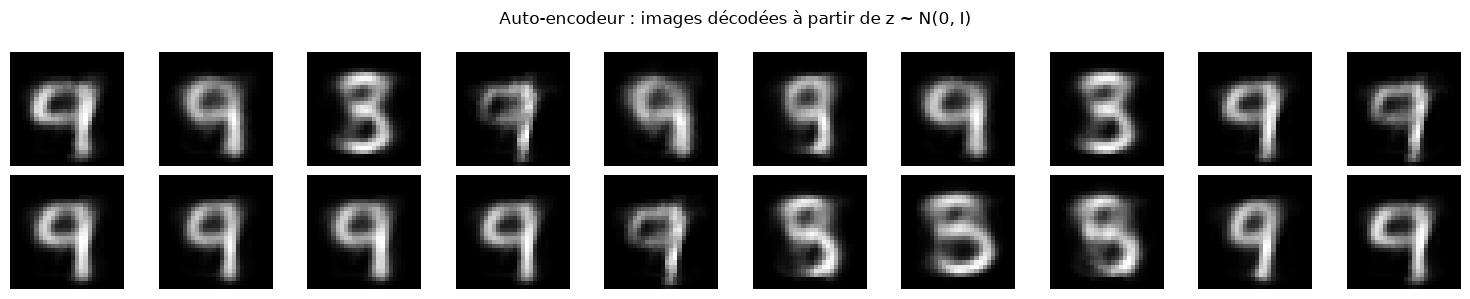

In [16]:
ae.eval()
with torch.no_grad():
    z = torch.randn(20, 2, device=device)
    samples = ae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("Auto-encodeur : images décodées à partir de z ~ N(0, I)")
plt.tight_layout()
plt.show()

**Observation :** l'espace latent de l'auto-encodeur n'est ni continu ni régulier, et il ne suit pas une loi connue. Un point choisi au hasard peut tomber dans une zone vide, et le décodeur produit alors une image peu réaliste. C'est ce qui motive le VAE.

## 4. Variational Auto-Encoder (VAE)

L'encodeur associe chaque image à une distribution q(z | x) = N(μ, σ²) au lieu d'un point unique.

**Reparameterization trick :** z = μ + σ ⊙ ε, avec ε ~ N(0, I), ce qui permet la rétropropagation.

**Loss :** L = L_rec + β · D_KL( q(z | x) ‖ N(0, I) ), avec D_KL = −½ Σ (1 + log σ² − μ² − σ²).

In [17]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [18]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [19]:
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)


def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()
    for epoch in range(epochs):
        total_loss = total_rec = total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=beta)

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)
        print(
            f"Epoch {epoch+1}/{epochs} | Loss={total_loss/n:.2f} | "
            f"Rec={total_rec/n:.2f} | KL={total_kl/n:.2f}"
        )


train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=194.17 | Rec=190.55 | KL=3.62
Epoch 2/20 | Loss=166.49 | Rec=161.55 | KL=4.94
Epoch 3/20 | Loss=161.35 | Rec=156.11 | KL=5.24
Epoch 4/20 | Loss=157.64 | Rec=152.18 | KL=5.46
Epoch 5/20 | Loss=155.30 | Rec=149.72 | KL=5.58
Epoch 6/20 | Loss=153.59 | Rec=147.92 | KL=5.67
Epoch 7/20 | Loss=152.16 | Rec=146.41 | KL=5.75
Epoch 8/20 | Loss=150.81 | Rec=144.95 | KL=5.86
Epoch 9/20 | Loss=149.63 | Rec=143.69 | KL=5.95
Epoch 10/20 | Loss=148.53 | Rec=142.48 | KL=6.05
Epoch 11/20 | Loss=147.65 | Rec=141.53 | KL=6.11
Epoch 12/20 | Loss=146.92 | Rec=140.76 | KL=6.16
Epoch 13/20 | Loss=146.24 | Rec=140.04 | KL=6.20
Epoch 14/20 | Loss=145.69 | Rec=139.45 | KL=6.24
Epoch 15/20 | Loss=145.06 | Rec=138.77 | KL=6.29
Epoch 16/20 | Loss=144.59 | Rec=138.27 | KL=6.32
Epoch 17/20 | Loss=144.11 | Rec=137.76 | KL=6.35
Epoch 18/20 | Loss=143.78 | Rec=137.41 | KL=6.37
Epoch 19/20 | Loss=143.49 | Rec=137.08 | KL=6.41
Epoch 20/20 | Loss=143.07 | Rec=136.64 | KL=6.43


### Évaluation : loss du VAE sur le test

In [20]:
@torch.no_grad()
def evaluate_vae(model, loader):
    model.eval()
    total_loss = total_rec = total_kl = 0
    for x, _ in loader:
        x = x.to(device)
        x_hat, mu, logvar = model(x)
        loss, rec, kl = vae_loss(x_hat, x, mu, logvar)
        total_loss += loss.item()
        total_rec += rec.item()
        total_kl += kl.item()
    n = len(loader.dataset)
    return total_loss / n, total_rec / n, total_kl / n


loss, rec, kl = evaluate_vae(vae, test_loader)
print(f"Test | Loss={loss:.2f} | Rec={rec:.2f} | KL={kl:.2f}")

Test | Loss=143.97 | Rec=137.62 | KL=6.35


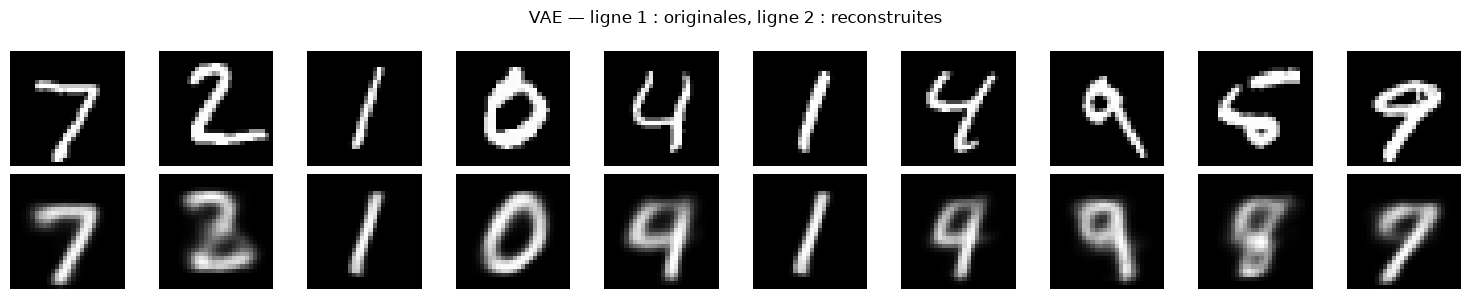

In [21]:
afficher_reconstructions(vae, "VAE", vae=True)

### Exploration : espace latent du VAE (on utilise μ)

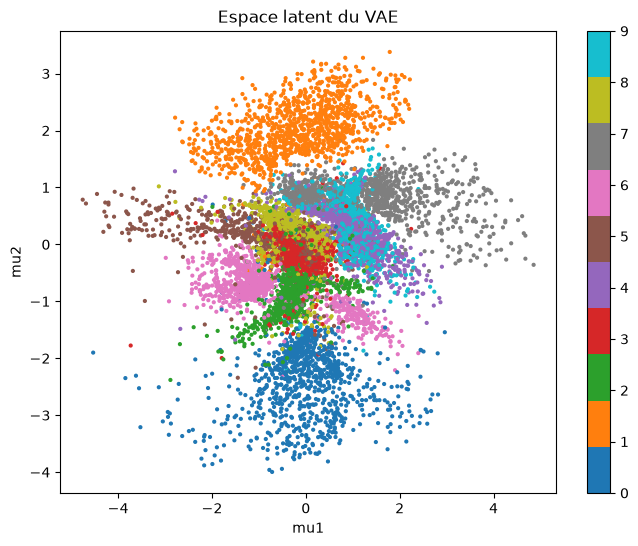

In [22]:
vae.eval()
mus, ys = [], []

with torch.no_grad():
    for x, y in test_loader:
        mu, logvar = vae.encode(x.to(device))
        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(MU[:, 0], MU[:, 1], c=Y, s=4, cmap="tab10")
plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
plt.show()

### Génération de nouvelles images : z ~ N(0, I), puis x_new = Decoder(z)

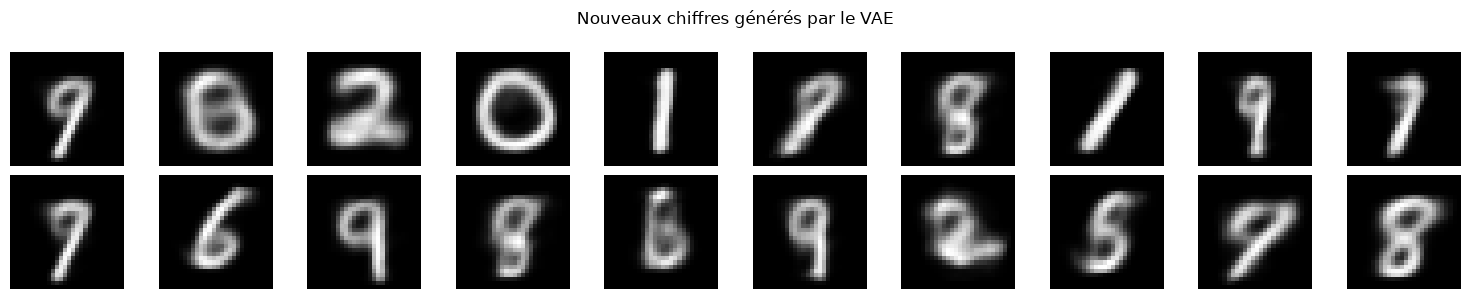

In [23]:
vae.eval()
with torch.no_grad():
    z = torch.randn(20, 2, device=device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
plt.show()

### Exploration continue de l'espace latent (grille 15 × 15)

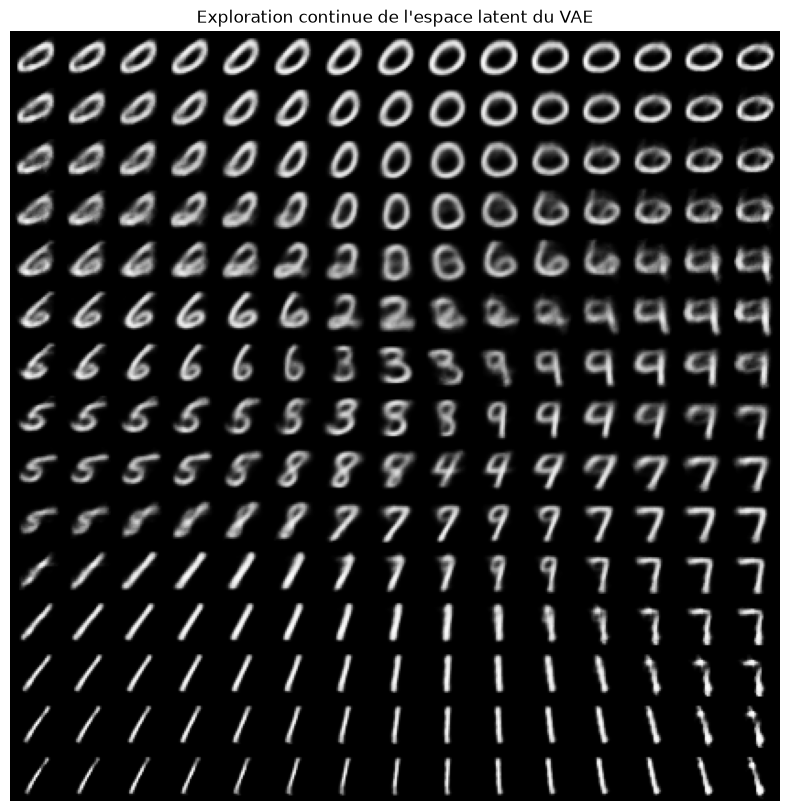

In [24]:
vae.eval()
n = 15
grid_x = np.linspace(-3, 3, n)
grid_y = np.linspace(-3, 3, n)
figure = np.zeros((28 * n, 28 * n))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            digit = vae.decode(z).cpu().numpy()[0, 0]
            figure[i*28:(i+1)*28, j*28:(j+1)*28] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
plt.show()

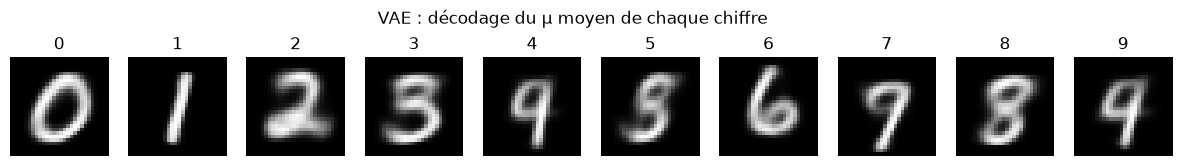

In [25]:
afficher_chiffres_moyens(vae, train_loader, "VAE : décodage du μ moyen de chaque chiffre", vae=True)

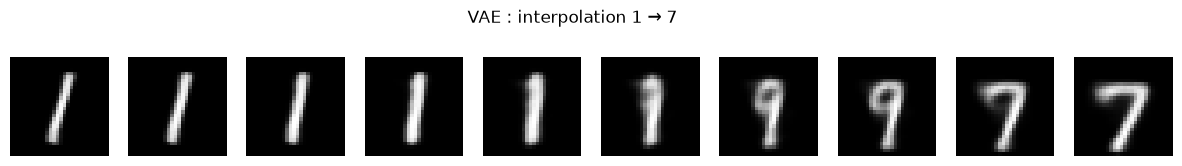

In [26]:
interpolation(vae, image_1, image_7, "VAE : interpolation 1 → 7", vae=True)